# Segmentation performance against a hand-corrected ground truth

Compares every segmentation of the store written by notebook 01 with the masks corrected in the Cellpose GUI
(notebook 02, `$MACROSEG_ANNOTATIONS/round_<NN>/<name>/`).

Cells are matched one to one by their overlap (IoU, intersection over union). At each IoU threshold:

| Measure | Definition | Says |
|---|---|---|
| AP | matched / (matched + false cells + missed cells) | overall quality (Cellpose's definition) |
| precision | matched / segmented cells | how many segmented cells are real |
| recall | matched / true cells | how many true cells are found |
| recall on hand-drawn cells | recall on the cells drawn in the GUI only | the cells the starting masks got wrong |

IoU 0.5 mostly says whether a cell is found; 0.75 and 0.9 whether its outline is right.

**Bias:** the ground truth was made by correcting one segmentation, so that one scores high
(its untouched cells are identical). A fair comparison needs an image whose masks were not used for training.

In [1]:
from pathlib import Path

import numpy as np
import tifffile
from spatialdata import read_zarr

from macroseg import paths
from macroseg.accuracy import corrected_region, plot_ap_curve, score_segmentations, worst_matches
from macroseg.annotation import corrected_masks, image_folder, load_annotations, summarize_rounds
from macroseg.config import load_config

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = load_config(ROOT / "configs" / "exp201_test_crop.yaml")
ANNOTATIONS = paths.path("MACROSEG_ANNOTATIONS")
ROUND = 1

/Users/massimoz/Documents/macroseg/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0. Annotation rounds
Every image of every round (`annotation.json`), then one line per round. `start_score`: the starting masks
scored against their correction; it should rise from round to round as the model improves.

In [2]:
annotations = load_annotations(ANNOTATIONS)
annotations

,round,image,role,status,exported_on,source,level,crop,pixel_size_um,zarr,...,counts.unchanged,counts.removed,counts.drawn,counts.changed_%,start_score.AP@0.5,start_score.precision@0.5,start_score.recall@0.5,start_score.AP@0.75,start_score.precision@0.75,start_score.recall@0.75
0,1,exp201_test_crop,train,complete,2026-10-22,/Users/massimoz/Documents/macroseg/data/input/...,0,"[2000, 4048, 2000, 4048]",0.17,/Users/massimoz/Documents/macroseg/data/runs/e...,...,1537,50,17,3.15,0.9656,0.9723,0.9929,0.9582,0.9685,0.9891


In [3]:
summarize_rounds(annotations)

,images,complete,test_images,cells_drawn,cells_removed,mean_changed_pct,mean_start_AP@0.5,mean_start_AP@0.75
round,,,,,,,,
1,1,1,0,17,50,3.15,0.9656,0.9582


## 1. Scores
One column per segmentation of the store, against the corrected masks of `ROUND`.

In [4]:
sdata = read_zarr(cfg.zarr)
segmentations = {step.labels: sdata.labels[step.labels].data.compute() for step in cfg.segmentation}
truth, hand_drawn = corrected_masks(image_folder(ANNOTATIONS, ROUND, cfg.name))

table = score_segmentations(truth, segmentations, thresholds=[0.5, 0.75, 0.9], truth_ids=hand_drawn)
table.rename(columns=lambda c: c.replace("subset_", "hand_drawn_")).T.round(3)

no parent found for <ome_zarr.reader.Label object at 0x11e88f770>: None
no parent found for <ome_zarr.reader.Label object at 0x11e967250>: None
no parent found for <ome_zarr.reader.Label object at 0x109754cd0>: None
no parent found for <ome_zarr.reader.Label object at 0x11ea008a0>: None


segmentation,nuclei,nuclei_expanded,membrane,membrane_dapi
true_cells,1554.000,1554.000,1554.000,1554.000
segmented_cells,1911.000,1911.000,1441.000,1587.000
hand_drawn_cells,17.000,17.000,17.000,17.000
AP@0.5,0.508,0.633,0.544,0.966
precision@0.5,0.611,0.703,0.732,0.972
recall@0.5,0.752,0.864,0.679,0.993
hand_drawn_recall@0.5,0.294,0.118,0.176,0.353
AP@0.75,0.087,0.321,0.244,0.958
precision@0.75,0.145,0.440,0.408,0.968
recall@0.75,0.178,0.541,0.378,0.989


### Only where the annotator changed something
The untouched cells are identical to the starting segmentation, so they inflate its score. Here only the
corrected region counts: the cells drawn or modified in the GUI and the starting cells removed. True and
segmented cells are kept when more than half of their pixels lie in it. Few cells: read big differences only.

In [ ]:
folder = image_folder(ANNOTATIONS, ROUND, cfg.name)
start = tifffile.imread(folder / "start_masks.tif")
region = corrected_region(start, truth)

region_table = score_segmentations(truth, segmentations, thresholds=[0.5, 0.75, 0.9], region=region)
region_table.T.round(3)

In [ ]:
region_curve = score_segmentations(
    truth, segmentations, thresholds=np.round(np.arange(0.5, 1.0, 0.05), 2), region=region
)
plot_ap_curve(region_curve, "AP");
plot_ap_curve(region_curve, "recall");

## 2. AP and recall against the IoU threshold
A curve that stays high to the right means precise outlines.

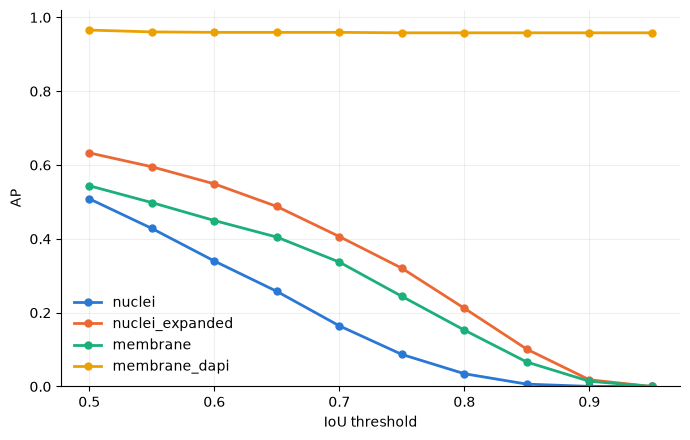

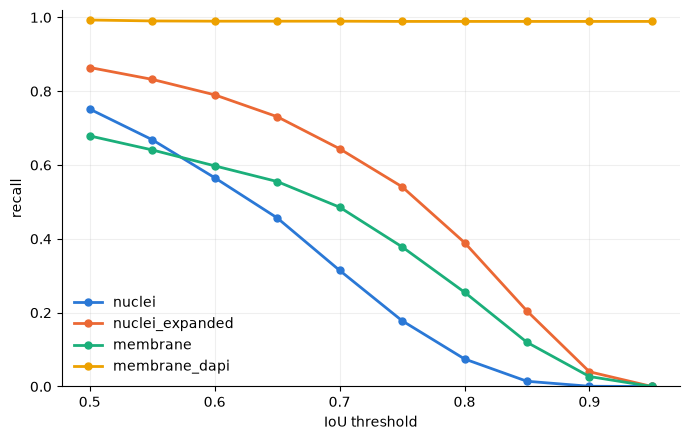

In [5]:
curve = score_segmentations(truth, segmentations, thresholds=np.round(np.arange(0.5, 1.0, 0.05), 2))
plot_ap_curve(curve, "AP");
plot_ap_curve(curve, "recall");

## 3. Cells to look at
True cells with the worst match in one segmentation (`iou` 0 = missed). `y`, `x`: centre in pixels,
to find them in the Cellpose GUI.

In [6]:
worst = worst_matches(truth, segmentations["membrane_dapi"])
worst["hand_drawn"] = worst["truth_ID"].isin(hand_drawn)
worst

,truth_ID,pred_ID,iou,y,x,hand_drawn
0,1543,916,0.067895,1062,1044,True
1,1549,1706,0.077984,1958,851,True
2,1551,1357,0.117376,1504,1309,True
3,1544,967,0.147640,1075,1531,True
4,1539,1012,0.238605,1165,660,True
5,1550,1435,0.311348,1587,1272,True
6,1540,935,0.359079,1008,376,True
7,1554,1457,0.381772,1632,1654,True
8,1542,891,0.440678,977,345,True
9,1548,1521,0.481545,1752,303,True
